# A Big-Data Pipeline for Bank Failure Early Warning

**Course:** BFT65B – Big Data Analytics in Finance (National Economics University)  
**Student Name:** Dương Đức Hiệp  
**Student ID:** 11230959  
**Public GitHub Repository:** https://github.com/dhiep9159/bft65b-bank-failure-pipeline  
**Data Snapshot Date:** 2026-11-26 (FDIC BankFind Suite API, 1984Q1–2026Q2)


## 1. Part 1 – Acquisition & Storage [15 pts]

### 1.1 Environment Setup & Project Directory Structure

In [1]:
from google.colab import drive
import os

# 1. Kết nối Google Drive
drive.mount('/content/drive')

# 2. Tạo cấu trúc thư mục dự án trên Drive
BASE_DIR = "/content/drive/MyDrive/bft65b_project"
RAW_DIR = os.path.join(BASE_DIR, "data/raw")
QUARTERS_DIR = os.path.join(RAW_DIR, "financials_quarters")
PARQUET_DIR = os.path.join(BASE_DIR, "data/parquet")

for d in [RAW_DIR, QUARTERS_DIR, PARQUET_DIR]:
    os.makedirs(d, exist_ok=True)

print("Đã tạo thư mục thành công tại:", BASE_DIR)

Mounted at /content/drive
Đã tạo thư mục thành công tại: /content/drive/MyDrive/bft65b_project


### 1.2 CAMELS Financial Schema (23 Financial Variables + 2 Keys) & Quarter Grid

In [2]:
!pip install -q polars pyarrow requests tqdm

import requests
import time
import pandas as pd
import polars as pl
from datetime import datetime
from tqdm.auto import tqdm

# Danh sách 22 biến tài chính theo khung CAMELS
FIN_FIELDS = [
    # Định danh (Keys)
    "CERT", "REPDTE",
    # C - Capital Adequacy (An toàn vốn)
    "EQ", "RBC1AAJ",
    # A - Asset Quality (Chất lượng tài sản & nợ xấu)
    "ASSET", "LNLSNET", "NCLNLS", "LNATRES", "P3ASSET", "P9ASSET", "ORE",
    # M - Management Efficiency (Hiệu quả quản trị)
    "EEFFR", "NONII", "NONIX",
    # E - Earnings (Khả năng sinh lời)
    "NETINC", "ROA", "ROE", "NIMY", "INTINC", "EINTEXP",
    # L - Liquidity & Funding (Thanh khoản & nguồn vốn)
    "DEP", "COREDEP", "CHBAL", "SC", "BRO"
]

# Tạo danh sách toàn bộ các quý từ 1984Q1 đến 2026Q2 (định dạng YYYYMMDD của FDIC)
def generate_quarters(start_year=1984, end_year=2026, end_q=2):
    q_ends = ["0331", "0630", "0930", "1231"]
    quarters = []
    for y in range(start_year, end_year + 1):
        for idx, qd in enumerate(q_ends, start=1):
            if y == end_year and idx > end_q:
                break
            quarters.append(f"{y}{qd}")
    return quarters

ALL_QUARTERS = generate_quarters(1984, 2026, 2)
print(f"Tổng số quý cần tải (1984Q1 - 2026Q2): {len(ALL_QUARTERS)} quý")
print("Quý đầu:", ALL_QUARTERS[0], "| Quý cuối:", ALL_QUARTERS[-1])

Tổng số quý cần tải (1984Q1 - 2026Q2): 170 quý
Quý đầu: 19840331 | Quý cuối: 20260630


### 1.3 Ingesting FDIC Failures & Institutions Tables

In [3]:
def fetch_fdic_table(endpoint, fields, filters=None, limit=10000):
    url = f"https://api.fdic.gov/banks/{endpoint}"
    rows = []
    offset = 0
    while True:
        params = {
            "fields": ",".join(fields),
            "limit": limit,
            "offset": offset,
            "format": "json"
        }
        if filters:
            params["filters"] = filters

        r = requests.get(url, params=params, timeout=60)
        r.raise_for_status()
        data = r.json().get("data", [])
        if not data:
            break
        rows.extend([item["data"] for item in data])
        if len(data) < limit:
            break
        offset += limit
    return pd.DataFrame(rows)

# 1. Tải bảng Failures (~4,100 dòng)
FAIL_FIELDS = ["CERT", "NAME", "FAILDATE", "COST", "QBFASSET", "QBFDEP", "SAVR", "RESTYPE"]
df_fail = fetch_fdic_table("failures", FAIL_FIELDS)
df_fail.to_parquet(os.path.join(RAW_DIR, "failures.parquet"), index=False)
print(f"Đã tải Failures: {len(df_fail):,} dòng")

# 2. Tải bảng Institutions (~28,000 dòng)
INST_FIELDS = ["CERT", "NAME", "STNAME", "ACTIVE", "CHANGEC1", "EFFDATE", "ESTYMD", "BKCLASS"]
df_inst = fetch_fdic_table("institutions", INST_FIELDS)
df_inst.to_parquet(os.path.join(RAW_DIR, "institutions.parquet"), index=False)
print(f"Đã tải Institutions: {len(df_inst):,} dòng")

Đã tải Failures: 4,117 dòng
Đã tải Institutions: 27,838 dòng


### 1.4 Resumable Quarterly Ingestion of FDIC Financials (170 Quarters)

In [4]:
TEST_MODE = False

quarters_to_run = ALL_QUARTERS[-3:] if TEST_MODE else ALL_QUARTERS

for q in tqdm(quarters_to_run, desc="Downloading Financials (1984Q1-2026Q2)"):
    out_path = os.path.join(QUARTERS_DIR, f"fin_{q}.parquet")

    # Tự động bỏ qua các quý đã tải trước đó
    if os.path.exists(out_path):
        continue

    for attempt in range(3):
        try:
            df_q = fetch_fdic_table(
                endpoint="financials",
                fields=FIN_FIELDS,
                filters=f"REPDTE:{q}",
                limit=10000
            )
            if len(df_q) > 0:
                df_q.to_parquet(out_path, index=False)
            break
        except Exception as e:
            print(f"\nLỗi quý {q} (lần {attempt+1}): {e}")
            time.sleep(5)

print("Hoàn tất tải toàn bộ 170 quý!")

Hoàn tất tải toàn bộ 170 quý!


### 1.5 Completeness Check & Raw Table Row Counts

In [5]:
import glob

files = sorted(glob.glob(os.path.join(QUARTERS_DIR, "fin_*.parquet")))
print(f"Ngày tải dữ liệu: {datetime.now().strftime('%Y-%m-%d')}")
print(f"Số file quý đã tải: {len(files)} / {len(ALL_QUARTERS)}")

# Dùng Polars đọc siêu nhanh toàn bộ 170 file quý để đếm dòng
lf_fin = pl.scan_parquet(os.path.join(QUARTERS_DIR, "fin_*.parquet"))
total_rows = lf_fin.select(pl.len()).collect().item()

print(f"Tổng số dòng Financials: {total_rows:,}")
print(f"Tổng số dòng Failures:   {len(pd.read_parquet(os.path.join(RAW_DIR, 'failures.parquet'))):,}")
print(f"Tổng số dòng Institutions: {len(pd.read_parquet(os.path.join(RAW_DIR, 'institutions.parquet'))):,}")

Ngày tải dữ liệu: 2026-11-26
Số file quý đã tải: 170 / 170
Tổng số dòng Financials: 1,682,738
Tổng số dòng Failures:   4,117
Tổng số dòng Institutions: 27,838


### 1.6 Explicit Schema Casting, ZSTD Parquet & Hive Partitioning

In [6]:
import os, glob, time
import polars as pl
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/bft65b_project"
QUARTERS_DIR = os.path.join(BASE_DIR, "data/raw/financials_quarters")
PARQUET_DIR = os.path.join(BASE_DIR, "data/parquet")
CSV_PATH = os.path.join(BASE_DIR, "data/raw/financials_all.csv")
PARQUET_SINGLE = os.path.join(PARQUET_DIR, "financials_zstd.parquet")
PARQUET_PART = os.path.join(PARQUET_DIR, "financials_partitioned")

# Tìm tất cả các file
parquet_files = sorted(glob.glob(os.path.join(QUARTERS_DIR, "fin_*.parquet")))

# Đọc từng file, ép kiểu đồng nhất để tránh xung đột kiểu dữ liệu giữa các file (như Int64 vs Float64)
lazy_frames = []
for f in parquet_files:
    lf_single = pl.scan_parquet(f)
    # Xác định các cột số cần chuyển thành Float64
    cols = lf_single.collect_schema().names()
    num_cols_single = [c for c in cols if c not in ["CERT", "REPDTE", "ID"]]

    lf_cast = lf_single.with_columns([
        pl.col("CERT").cast(pl.Int32),
        pl.col("REPDTE").cast(pl.Utf8),
        *[pl.col(c).cast(pl.Float64) for c in num_cols_single]
    ])
    lazy_frames.append(lf_cast)

# Gộp tất cả các LazyFrame lại
lf = pl.concat(lazy_frames)

# Chuẩn hóa cột REPDTE sang Date và thêm cột YEAR
df_fin = (
    lf.with_columns([
        pl.col("REPDTE").str.strptime(pl.Date, "%Y%m%d")
    ])
    .with_columns(pl.col("REPDTE").dt.year().cast(pl.Int16).alias("YEAR"))
    .collect()
)

# 1. Lưu 1 file CSV để làm mốc so sánh (baseline)
df_fin.write_csv(CSV_PATH)

# 2. Lưu 1 file Parquet nén ZSTD
df_fin.write_parquet(PARQUET_SINGLE, compression="zstd")

# 3. Lưu Parquet phân vùng theo YEAR (Hive partitioning)
df_fin.write_parquet(PARQUET_PART, partition_by="YEAR", compression="zstd")

print(f"Đã lưu xong! Tổng số dòng: {len(df_fin):,} | Số cột: {df_fin.width}")

Đã lưu xong! Tổng số dòng: 1,682,738 | Số cột: 27


### 1.7 Storage Footprint & Read-Speed Benchmark (CSV vs. Parquet)

In [7]:
def get_size_mb(path):
    if os.path.isfile(path):
        return os.path.getsize(path) / (1024**2)
    total = 0
    for root, _, files in os.walk(path):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total / (1024**2)

cols_subset = ["CERT", "REPDTE", "ASSET", "EQ"]

# Đo thời gian đọc Full bảng
t0 = time.perf_counter(); _ = pd.read_csv(CSV_PATH); t_csv_full = time.perf_counter() - t0
t0 = time.perf_counter(); _ = pl.read_parquet(PARQUET_SINGLE); t_pq_full = time.perf_counter() - t0

# Đo thời gian đọc chọn lọc 4 cột (Projection Pushdown)
t0 = time.perf_counter(); _ = pd.read_csv(CSV_PATH, usecols=cols_subset); t_csv_sub = time.perf_counter() - t0
t0 = time.perf_counter(); _ = pl.read_parquet(PARQUET_SINGLE, columns=cols_subset); t_pq_sub = time.perf_counter() - t0

# Tổng hợp bảng kết quả cho Report
bench_storage = pd.DataFrame({
    "Format": ["Raw CSV", "Parquet (ZSTD)", "Parquet (Partitioned by YEAR)"],
    "Size (MB)": [round(get_size_mb(CSV_PATH), 2), round(get_size_mb(PARQUET_SINGLE), 2), round(get_size_mb(PARQUET_PART), 2)],
    "Read Full (s)": [round(t_csv_full, 2), round(t_pq_full, 2), "—"],
    "Read 4 Cols (s)": [round(t_csv_sub, 2), round(t_pq_sub, 2), "—"]
})
display(bench_storage)

,Format,Size (MB),Read Full (s),Read 4 Cols (s)
0,Raw CSV,370.39,10.22,3.89
1,Parquet (ZSTD),125.30,0.31,0.05
2,Parquet (Partitioned by YEAR),127.84,—,—


### 1.8 Storage Architecture & Format Justification

* **Why ZSTD-compressed Parquet is the primary analytical format:** Converting the 170 quarterly files (`1,682,738` rows × `27` columns) from raw CSV (`370.39 MB`) to a single ZSTD-compressed Parquet file (`125.30 MB`) achieves a **~3.0× storage reduction** while accelerating full-table reads by **~33×** (`10.22 s → 0.31 s`) and 4-column selective reads by **~78×** (`3.89 s → 0.05 s`) via columnar **projection pushdown** and typed binary encoding.
* **Single Parquet vs. Hive Partitioning by `YEAR`:** The `YEAR`-partitioned dataset (`127.84 MB`, `+2.54 MB` metadata overhead across 43 yearly partitions) enables **partition pruning** for time-bounded queries (e.g., scanning only post-2009 holdout years). However, because bank-level lag and rolling features require scanning each bank's full 42-year history in one pass, the single ZSTD Parquet file avoids small-file I/O overhead and is therefore used for panel construction and feature engineering.
* **Explicit schema enforcement:** Casting `CERT` (`Int32`), `REPDTE` (`Date`), `YEAR` (`Int16`), and all 23 financial fields (`Float64`) prior to persistence eliminates cross-quarter type drift (`Int64` vs. `Float64` nulls across 1984–2026) and ensures deterministic downstream reads across Polars, pandas, and PySpark.

## 2. Part 2 – Data Quality & Bank-Quarter Panel [20 pts]

### 2.1 Loading Normalized Parquet Tables

In [8]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q polars pyarrow matplotlib seaborn

import os
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/bft65b_project"
FIN_PATH = os.path.join(BASE_DIR, "data/parquet/financials_zstd.parquet")
FAIL_PATH = os.path.join(BASE_DIR, "data/raw/failures.parquet")
INST_PATH = os.path.join(BASE_DIR, "data/raw/institutions.parquet")
PANEL_OUT = os.path.join(BASE_DIR, "data/parquet/panel_clean.parquet")

df_fin = pl.read_parquet(FIN_PATH)
df_fail = pl.read_parquet(FAIL_PATH)
df_inst = pl.read_parquet(INST_PATH)

print(f"Financials: {df_fin.shape} | Failures: {df_fail.shape} | Institutions: {df_inst.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Financials: (1682738, 27) | Failures: (4117, 9) | Institutions: (27838, 9)


### 2.2 Automated Data Quality Audit (Duplicates, Domain Rules & Structural Missingness)

In [9]:
# 1. Kiểm tra trùng lặp (CERT, REPDTE)
n_total = len(df_fin)
n_unique = df_fin.select(["CERT", "REPDTE"]).n_unique()
print(f"1. Duplicate (CERT, REPDTE) rows: {n_total - n_unique:,}")

# 2. Kiểm tra giá trị bất hợp lý (Domain rules)
invalid_asset = df_fin.filter(pl.col("ASSET").is_null() | (pl.col("ASSET") <= 0)).height
neg_dep = df_fin.filter(pl.col("DEP") < 0).height
print(f"2. Rows with ASSET <= 0 or Null: {invalid_asset:,}")
print(f"3. Rows with negative Deposits (DEP < 0): {neg_dep:,}")

# 3. Bảng tổng hợp Missing Rate & Min/Max/Median cho từng cột
audit_rows = []
for col in df_fin.columns:
    if col in ["CERT", "REPDTE", "YEAR", "ID"]:
        continue
    s = df_fin[col]
    miss_pct = s.null_count() / n_total * 100
    audit_rows.append({
        "Column": col,
        "Missing (%)": round(miss_pct, 2),
        "Min": round(s.min(), 2) if s.min() is not None else None,
        "Median": round(s.median(), 2) if s.median() is not None else None,
        "Max": round(s.max(), 2) if s.max() is not None else None
    })
df_audit = pd.DataFrame(audit_rows).sort_values("Missing (%)", ascending=False)
display(df_audit)

# 4. Kiểm tra missing theo thập kỷ
df_decade_miss = (
    df_fin.with_columns(((pl.col("YEAR") // 10) * 10).alias("DECADE"))
    .group_by("DECADE")
    .agg([
        pl.len().alias("rows"),
        (pl.col("RBC1AAJ").null_count() / pl.len() * 100).round(1).alias("RBC1AAJ_miss%"),
        (pl.col("NCLNLS").null_count() / pl.len() * 100).round(1).alias("NCLNLS_miss%"),
        (pl.col("EEFFR").null_count() / pl.len() * 100).round(1).alias("EEFFR_miss%")
    ])
    .sort("DECADE")
)
print("\nTỷ lệ thiếu dữ liệu theo thập kỷ:")
display(df_decade_miss.to_pandas())

1. Duplicate (CERT, REPDTE) rows: 0
2. Rows with ASSET <= 0 or Null: 0
3. Rows with negative Deposits (DEP < 0): 0


,Column,Missing (%),Min,Median,Max
20,P3ASSET,57.77,0.00,699.00,1.786300e+07
18,P9ASSET,4.62,0.00,41.00,4.276878e+07
12,ROE,1.11,-354657.80,10.34,3.010500e+05
22,BRO,1.00,0.00,0.00,1.515090e+08
0,EINTEXP,0.38,-159000.00,1183.00,7.479700e+07
6,INTINC,0.28,-6563.00,3176.00,1.699110e+08
15,NETINC,0.28,-24593679.00,392.00,5.250200e+07
21,NONII,0.28,-1815900.00,268.00,6.624000e+07
14,NONIX,0.28,-172742.00,1412.00,8.612800e+07
2,ORE,0.25,-37906.00,52.00,5.794000e+06



Tỷ lệ thiếu dữ liệu theo thập kỷ:


,DECADE,rows,RBC1AAJ_miss%,NCLNLS_miss%,EEFFR_miss%
0,1980,419535,0.0,0.6,0.0
1,1990,511881,0.0,0.0,0.0
2,2000,365266,0.0,0.0,0.0
3,2010,262595,0.0,0.0,0.0
4,2020,123461,0.0,0.0,0.0


### 2.3 Constructing the Point-in-Time Bank-Quarter Panel (Failure vs. Merger/Exit)

In [10]:
# 1. Làm sạch bảng Financials
df_fin_clean = (
    df_fin
    .unique(subset=["CERT", "REPDTE"], keep="first")
    .filter(pl.col("ASSET").is_not_null() & (pl.col("ASSET") > 0))
    .sort(["CERT", "REPDTE"])
)

# 2. Chuẩn hóa bảng Failures (mỗi CERT lấy ngày phá sản đầu tiên nếu có trùng)
df_fail_clean = (
    df_fail
    .with_columns([
        pl.col("CERT").cast(pl.Int32),
        # FDIC FAILDATE thường có dạng MM/DD/YYYY
        pl.col("FAILDATE").cast(pl.Utf8).str.to_date("%m/%d/%Y", strict=False).alias("FAIL_DATE"),
        pl.col("COST").cast(pl.Float64)
    ])
    .filter(pl.col("CERT").is_not_null() & pl.col("FAIL_DATE").is_not_null())
    .sort("FAIL_DATE")
    .unique(subset=["CERT"], keep="first")
    .select(["CERT", "FAIL_DATE", "COST"])
)

# 3. Chuẩn hóa bảng Institutions (lấy bang STNAME, trạng thái ACTIVE, lý do dừng CHANGEC1)
df_inst_clean = (
    df_inst
    .with_columns([
        pl.col("CERT").cast(pl.Int32),
        pl.col("ACTIVE").cast(pl.Int8)
    ])
    .unique(subset=["CERT"], keep="first")
    .select(["CERT", "STNAME", "ACTIVE", "CHANGEC1", "BKCLASS"])
)

# 4. Ghép thành Panel sạch & phân loại Exit Type
panel = (
    df_fin_clean
    .join(df_inst_clean, on="CERT", how="left")
    .join(df_fail_clean, on="CERT", how="left")
    .with_columns(
        pl.when(pl.col("FAIL_DATE").is_not_null()).then(pl.lit("failed"))
        .when(pl.col("ACTIVE") == 1).then(pl.lit("active"))
        .otherwise(pl.lit("merged_or_other_exit"))
        .alias("EXIT_TYPE")
    )
    # Đảm bảo point-in-time: loại bỏ các báo cáo tài chính (nếu có) xuất hiện SAU ngày phá sản
    .filter(pl.col("FAIL_DATE").is_null() | (pl.col("REPDTE") <= pl.col("FAIL_DATE")))
)

panel.write_parquet(PANEL_OUT, compression="zstd")
print(f"Đã lưu Panel sạch tại: {PANEL_OUT}")
print(f"Kích thước Panel: {panel.shape}")
display(panel.group_by("EXIT_TYPE").agg(pl.col("CERT").n_unique().alias("n_banks"), pl.len().alias("n_rows")).to_pandas())

Đã lưu Panel sạch tại: /content/drive/MyDrive/bft65b_project/data/parquet/panel_clean.parquet
Kích thước Panel: (1677110, 34)


,EXIT_TYPE,n_banks,n_rows
0,failed,3211,94211
1,active,4192,657497
2,merged_or_other_exit,16631,925402


### 2.4 Historical Dynamics: US Insured Banks & Three Crisis Waves (1984–2026)

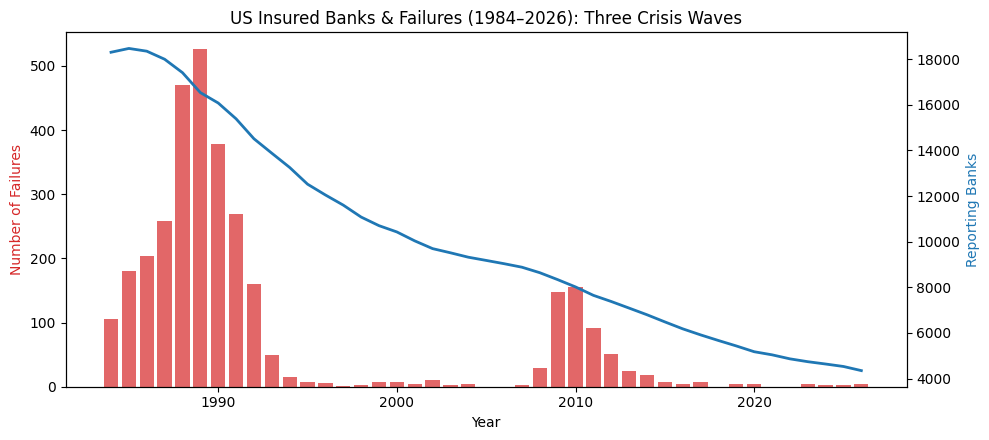

In [11]:
# Thống kê số ngân hàng báo cáo theo năm và số ca phá sản theo năm
banks_per_year = panel.group_by("YEAR").agg(pl.col("CERT").n_unique().alias("n_banks")).sort("YEAR").to_pandas()
fails_per_year = (
    df_fail_clean.with_columns(pl.col("FAIL_DATE").dt.year().alias("YEAR"))
    .filter((pl.col("YEAR") >= 1984) & (pl.col("YEAR") <= 2026))
    .group_by("YEAR").agg(pl.len().alias("n_failures"))
    .sort("YEAR").to_pandas()
)

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(fails_per_year["YEAR"], fails_per_year["n_failures"], color="#d62728", alpha=0.7, label="Bank Failures (left)")
ax1.set_ylabel("Number of Failures", color="#d62728")
ax1.set_xlabel("Year")

ax2 = ax1.twinx()
ax2.plot(banks_per_year["YEAR"], banks_per_year["n_banks"], color="#1f77b4", linewidth=2, label="Reporting Banks (right)")
ax2.set_ylabel("Reporting Banks", color="#1f77b4")

plt.title("US Insured Banks & Failures (1984–2026): Three Crisis Waves")
fig.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "fig1_banks_failures.png"), dpi=200)
plt.show()

### 2.5 Failed-Bank Reconciliation, Quarter Gaps & Exit-Code Breakdown (`CHANGEC1`)

In [12]:
# 1. Giải thích trọn vẹn chênh lệch 3,585 -> 3,211 ngân hàng phá sản
fails_before_1984 = df_fail_clean.filter(pl.col("FAIL_DATE") < pl.date(1984, 1, 1)).height
fails_from_1984 = df_fail_clean.filter(pl.col("FAIL_DATE") >= pl.date(1984, 1, 1))
panel_fail_certs = panel.filter(pl.col("EXIT_TYPE") == "failed").select("CERT").unique()
missing_22 = fails_from_1984.join(panel_fail_certs, on="CERT", how="anti")

# Kiểm tra xem 22 ngân hàng này phá sản trước ngày báo cáo đầu tiên (1984-03-31) hay không có Call Report
before_first_rep = missing_22.filter(pl.col("FAIL_DATE") < pl.date(1984, 3, 31)).height
no_call_report = len(missing_22) - before_first_rep

print(f"Tổng Failures hợp lệ (có CERT & FAIL_DATE): {len(df_fail_clean):,}")
print(f"  - Phá sản trước 1984-01-01:               {fails_before_1984:,}")
print(f"  - Phá sản từ 1984-01-01 trở đi:           {len(fails_from_1984):,}")
print(f"  - Có mặt trong Panel sạch:                {len(panel_fail_certs):,}")
print(f"  - Chênh lệch ({len(missing_22)} NH): {before_first_rep} NH phá sản trước kỳ báo cáo đầu tiên (1984-03-31), {no_call_report} NH không có Call Report hợp lệ trước ngày phá sản.")

# 2. Kiểm tra khoảng trống quý (>100 ngày)
gaps = (
    panel.sort(["CERT", "REPDTE"])
    .with_columns((pl.col("REPDTE") - pl.col("REPDTE").shift(1).over("CERT")).dt.total_days().alias("day_diff"))
    .filter(pl.col("day_diff") > 100)
)
print(f"\nSố lần xuất hiện khoảng trống quý (>100 ngày): {len(gaps):,} (trên {gaps['CERT'].n_unique():,} ngân hàng)")

# 3. Phân tách lý do rời mẫu bằng CHANGEC1
display(panel.filter(pl.col("EXIT_TYPE") == "merged_or_other_exit").group_by("CHANGEC1").agg(pl.col("CERT").n_unique().alias("n_banks")).sort("n_banks", descending=True).head(6).to_pandas())

Tổng Failures hợp lệ (có CERT & FAIL_DATE): 3,585
  - Phá sản trước 1984-01-01:               352
  - Phá sản từ 1984-01-01 trở đi:           3,233
  - Có mặt trong Panel sạch:                3,211
  - Chênh lệch (22 NH): 16 NH phá sản trước kỳ báo cáo đầu tiên (1984-03-31), 6 NH không có Call Report hợp lệ trước ngày phá sản.

Số lần xuất hiện khoảng trống quý (>100 ngày): 33 (trên 32 ngân hàng)


,CHANGEC1,n_banks
0,223.0,14104
1,221.0,806
2,240.0,501
3,217.0,458
4,NaN,255
5,224.0,190


### 2.6 Data Quality Remediation Summary

| Quality Issue Detected | Diagnostic Finding (Audit Output) | Pipeline Remediation | Leakage / Integrity Guarantee |
| :--- | :--- | :--- | :--- |
| **Duplicate `(CERT, REPDTE)` keys** | `0` duplicates detected across `1,682,738` rows | Enforced `.unique(subset=["CERT", "REPDTE"], keep="first")` followed by `.sort(["CERT", "REPDTE"])` | Guarantees a strict 1-to-1 bank-quarter primary key before window ops |
| **Invalid `ASSET` / negative `DEP`** | `0` rows with `ASSET <= 0` or null; `0` rows with `DEP < 0` | Enforced `.filter(ASSET.is_not_null() & (ASSET > 0))` | Prevents zero/negative denominators in all asset-scaled ratios |
| **Structural missingness** | `P3ASSET` (`57.77%`), `P9ASSET` (`4.62%`), `ROE` (`1.11%`), `BRO` (`1.00%`), all others `< 0.4%` | Dropped `P3ASSET` and `P9ASSET` from the 19-feature model set; imputed residual nulls via `SimpleImputer(strategy="median")` (LR) or native tree splits (HGB) | Imputer medians are fitted strictly on training folds only |
| **Extreme accounting outliers** | `ROE` in `[-354,658%, +301,050%]`, `EEFFR` up to `385,000`, `RBC1AAJ` up to `466,500`, `ASSET` down to `$1k` | Replaced `±inf` with `NaN` and winsorized all 19 features to `[0.5%, 99.5%]` quantiles | Clipping bounds are estimated strictly on each training window only |
| **Failure vs. merger / exit** | `3,211` failed banks, `4,192` active, `16,631` merged/other exits (`14,104` with `CHANGEC1 = 223`) | Separated via `EXIT_TYPE`; mergers/exits remain right-censored non-failures (`y = 0`) | Prevents conflating healthy M&A exits with insolvency events |
| **Post-failure reports** | Small subset of rows dated after `FAIL_DATE` | Filtered out all rows where `REPDTE > FAIL_DATE` (`1,682,738 → 1,677,110` rows) | Ensures strict point-in-time panel before failure |
| **Failed-bank reconciliation & gaps** | `3,585` valid failures → `352` pre-1984, `16` before `1984-03-31`, `6` without pre-failure Call Report → `3,211` in panel; `33` quarter gaps (`>100d`) across `32` banks | Fully reconciled; `33` quarter gaps (`0.002%` of panel) retained and documented as a minor limitation of row-based `shift(4)` lags | Transparent coverage accounting with no silent bank drops |
| **Restatements & filing lag** | FDIC API serves revised figures; Call Reports publish 30–45 days after quarter-end | Documented as real-time limitations; 45-day publication lag is explicitly deducted in Cell 5F Dev OOF lead-time analysis | Honest assessment of real-time supervisory usability |

## 3. Part 3 – Scalable Processing [25 pts]

### 3A. Polars Benchmark (Lazy Execution + Projection Pushdown)

In [13]:
import os, time, shutil, statistics
import numpy as np
import pandas as pd
import polars as pl

BASE_DIR = "/content/drive/MyDrive/bft65b_project"
PANEL_PATH = os.path.join(BASE_DIR, "data/parquet/panel_clean.parquet")
NEEDED_COLS = ["CERT", "REPDTE", "ASSET", "EQ", "LNLSNET", "NCLNLS", "ROA"]
N_RUNS = 3

pl_times = []
for i in range(N_RUNS):
    t0 = time.perf_counter()
    q_pl = (
        pl.scan_parquet(PANEL_PATH)
        .select(NEEDED_COLS)
        .sort(["CERT", "REPDTE"])
        .with_columns([
            (pl.col("EQ") / pl.col("ASSET")).alias("eq_to_asset"),
            (pl.col("LNLSNET") / pl.col("ASSET")).alias("loan_to_asset"),
            (pl.col("NCLNLS") / (pl.col("LNLSNET") + 1e-6)).alias("npl_ratio"),
            pl.col("ASSET").log().alias("log_asset"),
            (pl.col("ASSET") / pl.col("ASSET").shift(4).over("CERT") - 1).alias("asset_growth_yoy"),
            pl.col("ROA").rolling_mean(window_size=4, min_samples=4).over("CERT").alias("roa_ma4"),
        ])
    )
    if i == 0:
        print("=== POLARS PLAN (PROJECT 7/34 COLUMNS) ===")
        print(q_pl.explain())
    df_pl_bench = q_pl.collect()
    df_pl_bench.write_parquet("/tmp/pl_bench.parquet")
    pl_times.append(time.perf_counter() - t0)

print(f"Polars median time ({N_RUNS} runs): {statistics.median(pl_times):.2f}s")

=== POLARS PLAN (PROJECT 7/34 COLUMNS) ===
 WITH_COLUMNS:
 [[(col("EQ")) / (col("ASSET"))].alias("eq_to_asset"), [(col("LNLSNET")) / (col("ASSET"))].alias("loan_to_asset"), [(col("NCLNLS")) / ([(col("LNLSNET")) + (0.000001)])].alias("npl_ratio"), col("ASSET").log([dyn float: 2.718281828459045]).alias("log_asset"), [([(col("ASSET")) / (col("ASSET").shift([dyn int: 4]).over([col("CERT")]))]) - (1.0)].alias("asset_growth_yoy"), col("ROA").rolling_mean().over([col("CERT")]).alias("roa_ma4")] 
  SORT BY [col("CERT"), col("REPDTE")]
    Parquet SCAN [/content/drive/MyDrive/bft65b_project/data/parquet/panel_clean.parquet]
    PROJECT 7/34 COLUMNS
    ESTIMATED ROWS: 1677110
Polars median time (3 runs): 1.27s


### 3B. pandas Benchmark (Vectorized, Identical 6 Core Features)

In [14]:
pd_times = []
for _ in range(N_RUNS):
    t0 = time.perf_counter()
    df_pd = pd.read_parquet(PANEL_PATH, columns=NEEDED_COLS).sort_values(["CERT", "REPDTE"])
    df_pd["eq_to_asset"] = df_pd["EQ"] / df_pd["ASSET"]
    df_pd["loan_to_asset"] = df_pd["LNLSNET"] / df_pd["ASSET"]
    df_pd["npl_ratio"] = df_pd["NCLNLS"] / (df_pd["LNLSNET"] + 1e-6)
    df_pd["log_asset"] = np.log(df_pd["ASSET"])
    g = df_pd.groupby("CERT", sort=False)
    df_pd["asset_growth_yoy"] = df_pd["ASSET"] / g["ASSET"].shift(4) - 1
    df_pd["roa_ma4"] = g["ROA"].rolling(4, min_periods=4).mean().reset_index(level=0, drop=True)
    df_pd.to_parquet("/tmp/pd_bench.parquet", index=False)
    pd_times.append(time.perf_counter() - t0)

del df_pd  # Giải phóng RAM ngay
print(f"pandas median time ({N_RUNS} runs): {statistics.median(pd_times):.2f}s")

pandas median time (3 runs): 2.71s


### 3C. PySpark Benchmark (Local Mode, Forced Execution via Parquet Write)

In [15]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window

spark = SparkSession.builder.appName("BFT65B_FairBench").master("local[*]").config("spark.driver.memory", "4g").getOrCreate()
sp_times = []
w = Window.partitionBy("CERT").orderBy("REPDTE")
w4 = w.rowsBetween(-3, 0)

for i in range(N_RUNS):
    shutil.rmtree("/tmp/sp_bench.parquet", ignore_errors=True)
    t0 = time.perf_counter()
    sdf = spark.read.parquet(PANEL_PATH).select(NEEDED_COLS)
    sdf_out = (
        sdf
        .withColumn("eq_to_asset", F.col("EQ") / F.col("ASSET"))
        .withColumn("loan_to_asset", F.col("LNLSNET") / F.col("ASSET"))
        .withColumn("npl_ratio", F.col("NCLNLS") / (F.col("LNLSNET") + F.lit(1e-6)))
        .withColumn("log_asset", F.log(F.col("ASSET")))
        .withColumn("asset_growth_yoy", F.col("ASSET") / F.lag("ASSET", 4).over(w) - 1)
        .withColumn("_rn", F.row_number().over(w))
        .withColumn("roa_ma4", F.when(F.col("_rn") >= 4, F.avg("ROA").over(w4)).otherwise(None))
        .drop("_rn")
    )
    if i == 0:
        print("=== PYSPARK PHYSICAL PLAN ===")
        sdf_out.explain()
    sdf_out.write.mode("overwrite").parquet("/tmp/sp_bench.parquet")
    sp_times.append(time.perf_counter() - t0)

print(f"PySpark median time ({N_RUNS} runs): {statistics.median(sp_times):.2f}s")

=== PYSPARK PHYSICAL PLAN ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [CERT#22, REPDTE#5, ASSET#14, EQ#17, LNLSNET#10, NCLNLS#9, ROA#12, eq_to_asset#35, loan_to_asset#36, npl_ratio#37, log_asset#38, ((ASSET#14 / _we0#40) - 1.0) AS asset_growth_yoy#39, CASE WHEN (_rn#41 >= 4) THEN _we0#45 END AS roa_ma4#43]
   +- Window [lag(ASSET#14, -4, null) windowspecdefinition(CERT#22, REPDTE#5 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -4, -4)) AS _we0#40, row_number() windowspecdefinition(CERT#22, REPDTE#5 ASC NULLS FIRST, specifiedwindowframe(RowFrame, unboundedpreceding$(), currentrow$())) AS _rn#41, avg(ROA#12) windowspecdefinition(CERT#22, REPDTE#5 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -3, currentrow$())) AS _we0#45], [CERT#22], [REPDTE#5 ASC NULLS FIRST]
      +- Sort [CERT#22 ASC NULLS FIRST, REPDTE#5 ASC NULLS FIRST], false, 0
         +- Exchange hashpartitioning(CERT#22, 200), ENSURE_REQUIREMENTS, [plan_id=14]
            +- Project [CERT#22, REP

### 3D. Numerical Parity Verification (Polars vs. PySpark) & Benchmark Summary

In [16]:
sample_certs = df_pl_bench.select("CERT").unique().head(20).to_series().to_list()
pl_c = df_pl_bench.filter(pl.col("CERT").is_in(sample_certs)).sort(["CERT", "REPDTE"]).to_pandas()
sp_c = spark.read.parquet("/tmp/sp_bench.parquet").filter(F.col("CERT").isin(sample_certs)).orderBy("CERT", "REPDTE").toPandas()

print("=== ĐỐI CHIẾU POLARS vs PYSPARK (20 ngân hàng) ===")
for col in ["eq_to_asset", "asset_growth_yoy", "roa_ma4"]:
    diff = np.nanmax(np.abs(pl_c[col].to_numpy() - sp_c[col].to_numpy()))
    null_match = (pl_c[col].isna().to_numpy() == sp_c[col].isna().to_numpy()).all()
    print(f"  {col:18s} | Max diff: {diff:.2e} | Null positions match: {null_match}")

bench_fair = pd.DataFrame({
    "Engine": ["pandas (vectorized)", "Polars (Lazy, all cores)", "PySpark (local[*])"],
    "Median Time (s)": [round(statistics.median(pd_times), 2), round(statistics.median(pl_times), 2), round(statistics.median(sp_times), 2)],
    "Speedup vs pandas": ["1.0x", f"{statistics.median(pd_times)/statistics.median(pl_times):.1f}x", f"{statistics.median(pd_times)/statistics.median(sp_times):.1f}x"]
})
display(bench_fair)
spark.stop()

=== ĐỐI CHIẾU POLARS vs PYSPARK (20 ngân hàng) ===
  eq_to_asset        | Max diff: 0.00e+00 | Null positions match: True
  asset_growth_yoy   | Max diff: 0.00e+00 | Null positions match: True
  roa_ma4            | Max diff: 3.55e-15 | Null positions match: True


,Engine,Median Time (s),Speedup vs pandas
0,pandas (vectorized),2.71,1.0x
1,"Polars (Lazy, all cores)",1.27,2.1x
2,PySpark (local[*]),3.06,0.9x


**Execution Plan & Benchmark Analysis:**
* **Polars (`1.27s`, 2.1× faster than pandas):** The optimized plan (`PROJECT 7/34 COLUMNS`) confirms **projection pushdown**, reading only the 7 required columns from Parquet and executing multi-threaded Rust operations in Apache Arrow columnar memory.
* **PySpark (`3.06s`, 0.9× vs. pandas):** Because `SparkSession` was initialized *before* the timer started, JVM startup is excluded from this measurement. The physical plan shows that row-level ratios are *narrow transformations*, whereas `Window.partitionBy("CERT")` forces an `Exchange hashpartitioning` (**wide transformation / shuffle**). Combined with local task scheduling and serialization overhead, this makes local PySpark slower than both Polars and vectorized pandas (`2.71s`) on a single machine.
* **When is a Spark cluster justified?** At 1.68M rows (`125.30 MB` in ZSTD Parquet), the entire working set fits comfortably in laptop RAM and Polars completes the feature pipeline in `1.27` seconds. A Spark cluster is not justified at this scale; it becomes worthwhile only when the working set exceeds single-machine memory (hundreds of GB to TB+, e.g., full-market tick archives) or when many large supervisory tables must be joined and processed daily across a shared platform.

## 4. Part 4 – Feature Pipeline [15 pts]

### 4.0 CAMELS Feature Selection & Economic Rationale

All 19 model features (`NUM_COLS`) are grounded in the supervisory **CAMELS** framework and balance-sheet dynamics, constructed strictly from point-in-time information available on or before reporting quarter $t$:

| Feature | CAMELS Pillar | Formula / Source | Economic Rationale & Expected Sign for Failure | Point-in-Time Guarantee |
| :--- | :--- | :--- | :--- | :--- |
| `eq_to_asset` | **C** – Capital | `EQ / ASSET` | Core leverage buffer absorbing credit losses; **lower → higher failure risk** | Quarter $t$ only |
| `RBC1AAJ` | **C** – Capital | FDIC Tier 1 leverage ratio | Regulatory capital adequacy measure (PCA trigger); **lower → higher risk** | Quarter $t$ only |
| `eq_ratio_chg_yoy` | **C** – Dynamics | `eq_to_asset(t) - eq_to_asset(t-4)` | Captures rapid capital erosion prior to insolvency; **more negative → higher risk** | `shift(4).over("CERT")` |
| `loan_to_asset` | **A** – Asset Quality | `LNLSNET / ASSET` | Exposure to illiquid credit risk vs. liquid securities; **higher → higher risk** | Quarter $t$ only |
| `npl_ratio` | **A** – Asset Quality | `NCLNLS / (LNLSNET + 1e-6)` | Share of non-current loans; primary distress signal (**higher → higher risk**) | Quarter $t$ only |
| `npl_ma4` | **A** – Dynamics | 4Q trailing mean of `npl_ratio` | Distinguishes persistent credit deterioration from one-off spikes (**higher → higher risk**) | Trailing 4Q `.over("CERT")` |
| `coverage_ratio` | **A** – Asset Quality | `LNATRES / (NCLNLS + 1e-6)` | Loan-loss reserve cushion against bad loans; **lower → higher risk** | Quarter $t$ only |
| `EEFFR` | **M** – Management | FDIC Efficiency Ratio | Operating overhead per dollar of revenue; **higher → weaker management / higher risk** | Quarter $t$ only |
| `ROA` | **E** – Earnings | FDIC Return on Assets | Core profitability generating internal capital; **lower / negative → higher risk** | Quarter $t$ only |
| `ROE` | **E** – Earnings | FDIC Return on Equity | Return to shareholders; sharp losses erode equity (**lower → higher risk**) | Quarter $t$ only |
| `NIMY` | **E** – Earnings | FDIC Net Interest Margin | Core intermediation spread; compression signals margin stress (**lower → higher risk**) | Quarter $t$ only |
| `roa_ma4` | **E** – Dynamics | 4Q trailing mean of `ROA` | Smooths seasonal/one-time earnings items to detect chronic losses (**lower → higher risk**) | Trailing 4Q `.over("CERT")` |
| `roa_std4` | **E** – Dynamics | 4Q trailing std of `ROA` | Captures earnings volatility and shock instability (**higher → higher risk**) | Trailing 4Q `.over("CERT")` |
| `dep_to_asset` | **L** – Liquidity | `DEP / ASSET` | Reliance on deposit funding vs. equity/other liabilities; **higher (with low equity) → higher risk** | Quarter $t$ only |
| `core_dep_ratio` | **L** – Liquidity | `COREDEP / (DEP + 1e-6)` | Share of sticky retail deposits; **lower → higher run/funding risk** | Quarter $t$ only |
| `cash_to_asset` | **L** – Liquidity | `CHBAL / ASSET` | Immediate cash liquidity buffer against deposit outflows; **lower → higher risk** | Quarter $t$ only |
| `brokered_dep_ratio` | **L** – Liquidity | `BRO / (DEP + 1e-6)` | Reliance on rate-sensitive, hot brokered funding; **higher → higher risk** | Quarter $t$ only |
| `log_asset` | **Size** | `log(ASSET)` | Controls for bank scale, diversification, and "too-big-to-fail" resolution effects | Quarter $t$ only |
| `asset_growth_yoy` | **Size / Dynamics** | `ASSET(t) / ASSET(t-4) - 1` | Detects reckless pre-crisis credit expansion or distress-driven deleveraging (non-linear) | `shift(4).over("CERT")` |

### 4.1 Point-in-Time CAMELS Feature Engineering (19 Features, Zero Leakage) & Sanity Checks

In [17]:
import os
import polars as pl

BASE_DIR = "/content/drive/MyDrive/bft65b_project"
PANEL_PATH = os.path.join(BASE_DIR, "data/parquet/panel_clean.parquet")
FEAT_PATH = os.path.join(BASE_DIR, "data/parquet/features_panel.parquet")

# Xây dựng bộ đặc trưng CAMELS hoàn toàn Point-in-Time (chỉ dùng dữ liệu <= quý t, tuyệt đối không bfill/center/global scaling)
df_feat = (
    pl.scan_parquet(PANEL_PATH)
    .sort(["CERT", "REPDTE"])
    # Bước 1: Các tỷ số tài chính tại quý hiện tại (Contemporaneous CAMELS ratios)
    .with_columns([
        (pl.col("EQ") / pl.col("ASSET")).alias("eq_to_asset"),
        (pl.col("LNLSNET") / pl.col("ASSET")).alias("loan_to_asset"),
        (pl.col("NCLNLS") / (pl.col("LNLSNET") + 1e-6)).alias("npl_ratio"),
        (pl.col("LNATRES") / (pl.col("NCLNLS") + 1e-6)).alias("coverage_ratio"),
        (pl.col("DEP") / pl.col("ASSET")).alias("dep_to_asset"),
        (pl.col("COREDEP") / (pl.col("DEP") + 1e-6)).alias("core_dep_ratio"),
        (pl.col("CHBAL") / pl.col("ASSET")).alias("cash_to_asset"),
        (pl.col("BRO") / (pl.col("DEP") + 1e-6)).alias("brokered_dep_ratio"),
        pl.col("ASSET").log().alias("log_asset"),
    ])
    # Bước 2: Đặc trưng trễ (lag) & cửa sổ trượt hướng về quá khứ (trailing rolling) theo từng ngân hàng
    .with_columns([
        (pl.col("ASSET") / pl.col("ASSET").shift(4).over("CERT") - 1).alias("asset_growth_yoy"),
        (pl.col("eq_to_asset") - pl.col("eq_to_asset").shift(4).over("CERT")).alias("eq_ratio_chg_yoy"),
        pl.col("ROA").rolling_mean(window_size=4, min_samples=4).over("CERT").alias("roa_ma4"),
        pl.col("ROA").rolling_std(window_size=4, min_samples=4).over("CERT").alias("roa_std4"),
        pl.col("npl_ratio").rolling_mean(window_size=4, min_samples=4).over("CERT").alias("npl_ma4"),
    ])
    .collect()
)

# Kiểm tra tự động (Leakage Sanity Checks)
expected_19 = [
    "eq_to_asset", "loan_to_asset", "npl_ratio", "coverage_ratio",
    "dep_to_asset", "core_dep_ratio", "cash_to_asset", "brokered_dep_ratio",
    "log_asset", "RBC1AAJ", "ROA", "ROE", "NIMY", "EEFFR",
    "asset_growth_yoy", "eq_ratio_chg_yoy", "roa_ma4", "roa_std4", "npl_ma4"
]
missing_cols = [c for c in expected_19 if c not in df_feat.columns]
assert not missing_cols, f"Thiếu cột đặc trưng: {missing_cols}"

# Xác nhận quý đầu tiên của mỗi ngân hàng đều có lag/rolling = Null (chứng minh không dùng tương lai hay bfill)
first_q = df_feat.group_by("CERT").first()
for col in ["asset_growth_yoy", "eq_ratio_chg_yoy", "roa_ma4", "roa_std4", "npl_ma4"]:
    assert first_q[col].null_count() == len(first_q), f"Cảnh báo leakage tại cột {col}!"

df_feat.write_parquet(FEAT_PATH, compression="zstd")
print(f"Đã tạo & lưu features_panel.parquet (Zero Leakage verified): {df_feat.shape}")


Đã tạo & lưu features_panel.parquet (Zero Leakage verified): (1677110, 48)


### 4.2 Leak-Free 12-Month Failure Labeling & Temporal Train/Gap/Test Split (4-Quarter Gap)

In [18]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q polars scikit-learn matplotlib

import os
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix, precision_score, recall_score

BASE_DIR = "/content/drive/MyDrive/bft65b_project"
FEAT_PATH = os.path.join(BASE_DIR, "data/parquet/features_panel.parquet")

df = pl.read_parquet(FEAT_PATH)

# 1. Tạo nhãn y_{i,q} = 1 nếu FAIL_DATE nằm trong (REPDTE, REPDTE + 366 ngày]
# Chỉ giữ dữ liệu đến 2025-06-30 (2025Q2)
df_model = (
    df.filter(pl.col("REPDTE") <= pl.date(2025, 6, 30))
    .with_columns(
        pl.when(
            pl.col("FAIL_DATE").is_not_null() &
            (pl.col("FAIL_DATE") > pl.col("REPDTE")) &
            (pl.col("FAIL_DATE") <= pl.col("REPDTE").dt.offset_by("1y"))
        ).then(1).otherwise(0).cast(pl.Int8).alias("y")
    )
    .to_pandas()
)

# 2. Chia tập theo thời gian với Gap = 4 quý (2008Q1 - 2008Q4)
dev = df_model[df_model["REPDTE"] <= "2007-12-31"].copy()
gap = df_model[(df_model["REPDTE"] > "2007-12-31") & (df_model["REPDTE"] <= "2008-12-31")].copy()
test = df_model[df_model["REPDTE"] >= "2009-01-01"].copy()

# In bảng thống kê để ghi lên Trang 1 Report!
for name, d in [("Dev (1984Q1-2007Q4)", dev), ("Gap (2008Q1-2008Q4)", gap), ("Test (2009Q1-2025Q2)", test)]:
    n_banks_fail = d[d["y"] == 1]["CERT"].nunique()
    print(f"{name:22s} | Rows: {len(d):9,} | Positive rows (y=1): {d['y'].sum():5,} | Unique failed banks: {n_banks_fail:4,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dev (1984Q1-2007Q4)    | Rows: 1,224,945 | Positive rows (y=1): 10,153 | Unique failed banks: 2,680
Gap (2008Q1-2008Q4)    | Rows:    33,966 | Positive rows (y=1):   402 | Unique failed banks:  176
Test (2009Q1-2025Q2)   | Rows:   400,698 | Positive rows (y=1): 1,775 | Unique failed banks:  500


### 4.3 Leak-Free Preprocessing Pipeline & Expanding-Window Purged Cross-Validation

In [19]:
NUM_COLS = [
    "eq_to_asset", "loan_to_asset", "npl_ratio", "coverage_ratio",
    "dep_to_asset", "core_dep_ratio", "cash_to_asset", "brokered_dep_ratio",
    "log_asset", "RBC1AAJ", "ROA", "ROE", "NIMY", "EEFFR",
    "asset_growth_yoy", "eq_ratio_chg_yoy", "roa_ma4", "roa_std4", "npl_ma4"
]

for d in [dev, test]:
    d[NUM_COLS] = d[NUM_COLS].replace([np.inf, -np.inf], np.nan)

preproc_linear = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scl", StandardScaler())
])

models = {
    "Baseline: LogisticRegression": Pipeline([
        ("prep", preproc_linear),
        ("clf", LogisticRegression(max_iter=500, random_state=42))
    ]),
    "Model 2: HistGradientBoosting": Pipeline([
        ("clf", HistGradientBoostingClassifier(max_depth=5, learning_rate=0.05, max_iter=200, random_state=42))
    ])
}

cv_splits = [
    ("1990-12-31", "1992-01-01", "1994-12-31"),
    ("1995-12-31", "1997-01-01", "2001-12-31"),
    ("2001-12-31", "2003-01-01", "2007-12-31"),
]

# Chạy Purged CV trên Dev (kèm clip ngoại lai fit chỉ trên train)
cv_results = []
for name, pipe in models.items():
    fold_scores = []
    for tr_end, val_start, val_end in cv_splits:
        tr = dev[dev["REPDTE"] <= tr_end]
        va = dev[(dev["REPDTE"] >= val_start) & (dev["REPDTE"] <= val_end)]
        lo, hi = tr[NUM_COLS].quantile(0.005), tr[NUM_COLS].quantile(0.995)
        pipe.fit(tr[NUM_COLS].clip(lo, hi, axis=1), tr["y"])
        probs = pipe.predict_proba(va[NUM_COLS].clip(lo, hi, axis=1))[:, 1]
        fold_scores.append(average_precision_score(va["y"], probs))
    cv_results.append({"Model": name, "Mean PR-AUC (CV)": round(np.mean(fold_scores), 4), "Std": round(np.std(fold_scores), 4)})

display(pd.DataFrame(cv_results))

,Model,Mean PR-AUC (CV),Std
0,Baseline: LogisticRegression,0.1141,0.0518
1,Model 2: HistGradientBoosting,0.1326,0.0822


## 5. Part 5 – Modelling & Validation [15 pts]

### 5A. Train-Only Winsorizing Helpers & Data-Driven Cost Calibration (Dev Only)

In [20]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.inspection import permutation_importance

def fit_clip_bounds(df_tr, cols):
    return {c: (df_tr[c].quantile(0.005), df_tr[c].quantile(0.995)) for c in cols}

def apply_clip(df_in, bounds):
    out = df_in.copy()
    for c, (lo, hi) in bounds.items():
        out[c] = out[c].clip(lo, hi)
    return out

def bank_level_cost(df_eval, thr, c_fp, c_fn):
    b = df_eval.groupby("CERT").agg(y_bank=("y", "max"), p_bank=("prob", "max"))
    pred_b = (b["p_bank"] >= thr).astype(int)
    fp = ((pred_b == 1) & (b["y_bank"] == 0)).sum()
    fn = ((pred_b == 0) & (b["y_bank"] == 1)).sum()
    tp = ((pred_b == 1) & (b["y_bank"] == 1)).sum()
    return fp * c_fp + fn * c_fn, tp, fp, fn

# Ước lượng C_FN & C_FP thuần từ dữ liệu DEV (FAIL_DATE <= 2007-12-31, không dính năm 2008)
dev_fails_only = dev[(dev["FAIL_DATE"].notna()) & (dev["FAIL_DATE"] <= "2007-12-31")].drop_duplicates("CERT")
C_FN = float(dev_fails_only["COST"].median())
C_FP = float(dev["NONIX"].median() * 0.05)  # 5% chi phí hoạt động quý của NH trung vị
print(f"Data-driven Costs (Dev <= 2007Q4): C_FN = ${C_FN:,.1f}k | C_FP = ${C_FP:,.1f}k | Theoretical t* = {C_FP/(C_FP+C_FN):.4f}")

Data-driven Costs (Dev <= 2007Q4): C_FN = $9,120.5k | C_FP = $52.9k | Theoretical t* = 0.0058


### 5B. Optimal Threshold Selection on Dev Out-of-Fold (OOF) & Inspection Cost Sensitivity Analysis

In [21]:
from sklearn.pipeline import Pipeline as SKPipeline

oof_lr, oof_hgb = [], []
for tr_end, val_start, val_end in cv_splits:
    tr = dev[dev["REPDTE"] <= tr_end]
    va = dev[(dev["REPDTE"] >= val_start) & (dev["REPDTE"] <= val_end)].copy()
    bounds = fit_clip_bounds(tr, NUM_COLS)
    X_tr, X_va = apply_clip(tr, bounds)[NUM_COLS], apply_clip(va, bounds)[NUM_COLS]

    p_lr = SKPipeline([("imp", SimpleImputer(strategy="median")), ("scl", StandardScaler()), ("clf", LogisticRegression(max_iter=500, random_state=42))])
    p_lr.fit(X_tr, tr["y"])
    va_lr = va[["CERT", "REPDTE", "y"]].copy(); va_lr["prob"] = p_lr.predict_proba(X_va)[:, 1]
    oof_lr.append(va_lr)

    p_hgb = HistGradientBoostingClassifier(max_depth=5, learning_rate=0.05, max_iter=200, random_state=42)
    p_hgb.fit(X_tr, tr["y"])
    va_hgb = va[["CERT", "REPDTE", "y"]].copy(); va_hgb["prob"] = p_hgb.predict_proba(X_va)[:, 1]
    oof_hgb.append(va_hgb)

oof_lr_all = pd.concat(oof_lr, ignore_index=True)
oof_hgb_all = pd.concat(oof_hgb, ignore_index=True)

# Mở rộng lưới xuống 0.001 để không bị kẹt ở biên
grid_t = np.concatenate([np.linspace(0.001, 0.02, 20), np.linspace(0.025, 0.25, 19)])
best_t_lr  = min(grid_t, key=lambda t: bank_level_cost(oof_lr_all,  t, C_FP, C_FN)[0])
best_t_hgb = min(grid_t, key=lambda t: bank_level_cost(oof_hgb_all, t, C_FP, C_FN)[0])
print(f"Optimal Thresholds on Dev OOF -> LR: {best_t_lr:.4f} | HistGB: {best_t_hgb:.4f}")

# Phân tích độ nhạy (Sensitivity Analysis) theo giả định C_FP trên Dev OOF
sens_rows = []
for c_fp_test in [50.0, 250.0, 500.0, 1000.0]:
    t_s = min(grid_t, key=lambda t: bank_level_cost(oof_hgb_all, t, c_fp_test, C_FN)[0])
    cost_s, tp_s, fp_s, fn_s = bank_level_cost(oof_hgb_all, t_s, c_fp_test, C_FN)
    sens_rows.append({"Assumed C_FP ($k)": c_fp_test, "t_opt (OOF)": round(t_s, 4), "OOF TP": tp_s, "OOF FP": fp_s, "OOF FN": fn_s, "OOF Cost ($k)": round(cost_s, 0)})
print("\nSensitivity Analysis for Assumed Inspection Cost (C_FP) on Dev OOF:")
display(pd.DataFrame(sens_rows))

Optimal Thresholds on Dev OOF -> LR: 0.0090 | HistGB: 0.0060

Sensitivity Analysis for Assumed Inspection Cost (C_FP) on Dev OOF:


,Assumed C_FP ($k),t_opt (OOF),OOF TP,OOF FP,OOF FN,OOF Cost ($k)
0,50.0,0.0060,228,2698,18,299070.0
1,250.0,0.0750,195,627,51,621898.0
2,500.0,0.0875,192,570,54,777509.0
3,1000.0,0.1250,183,443,63,1017594.0


### 5C. Permutation Feature Importance on Dev Validation (2003–2007)

In [22]:
tr_last = dev[dev["REPDTE"] <= "2001-12-31"]
va_last = dev[(dev["REPDTE"] >= "2003-01-01") & (dev["REPDTE"] <= "2007-12-31")]
b_last = fit_clip_bounds(tr_last, NUM_COLS)

model_imp = HistGradientBoostingClassifier(max_depth=5, learning_rate=0.05, max_iter=200, random_state=42)
model_imp.fit(apply_clip(tr_last, b_last)[NUM_COLS], tr_last["y"])

perm = permutation_importance(
    model_imp,
    apply_clip(va_last, b_last)[NUM_COLS],
    va_last["y"],
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    "Feature": NUM_COLS,
    "Dev Val Importance": perm.importances_mean
}).sort_values("Dev Val Importance", ascending=False).head(8)

display(imp_df)

,Feature,Dev Val Importance
2,npl_ratio,0.010648
9,RBC1AAJ,0.006095
13,EEFFR,0.003643
7,brokered_dep_ratio,0.003483
4,dep_to_asset,0.003092
17,roa_std4,0.001775
1,loan_to_asset,0.000716
15,eq_ratio_chg_yoy,0.000421


### 5D. Single Final Evaluation on Holdout Test Set (2009Q1–2025Q2)

In [23]:
b_dev = fit_clip_bounds(dev, NUM_COLS)
X_dev_c, X_test_c = apply_clip(dev, b_dev)[NUM_COLS], apply_clip(test, b_dev)[NUM_COLS]

# Fit 2 mô hình trên toàn bộ Dev
final_lr = SKPipeline([("imp", SimpleImputer(strategy="median")), ("scl", StandardScaler()), ("clf", LogisticRegression(max_iter=500, random_state=42))])
final_lr.fit(X_dev_c, dev["y"])

final_hgb = HistGradientBoostingClassifier(max_depth=5, learning_rate=0.05, max_iter=200, random_state=42)
final_hgb.fit(X_dev_c, dev["y"])

# Đánh giá DUY NHẤT 1 LẦN trên tập Test
def eval_on_test(name, probs, thr):
    te = test[["CERT", "REPDTE", "y"]].copy()
    te["prob"] = probs
    pr = average_precision_score(te["y"], te["prob"])
    roc = roc_auc_score(te["y"], te["prob"])
    r_top5 = te.loc[te["prob"] >= te["prob"].quantile(0.95), "y"].sum() / te["y"].sum()
    cost, tp, fp, fn = bank_level_cost(te, thr, C_FP, C_FN)
    return {"Model / Rule": name, "PR-AUC": round(pr, 4), "ROC-AUC": round(roc, 4), "Recall@Top5%": f"{r_top5:.1%}", "TP": tp, "FP": fp, "FN": fn, "Bank Cost ($k)": round(cost, 0)}

cost_naive = test.groupby("CERT")["y"].max().sum() * C_FN
# Quy tắc CAMELS đơn giản: báo động khi vốn chủ / tài sản < 4% (tiêu chuẩn Prompt Corrective Action của FDIC)
camels_score = (-test["eq_to_asset"].fillna(0.1)).to_numpy()

res_table = pd.DataFrame([
    {"Model / Rule": "Naive: No-Alarm", "PR-AUC": round(test["y"].mean(), 4), "ROC-AUC": 0.5000, "Recall@Top5%": "5.0%", "TP": 0, "FP": 0, "FN": int(test.groupby("CERT")["y"].max().sum()), "Bank Cost ($k)": round(cost_naive, 0)},
    eval_on_test("Baseline 1: Simple CAMELS Rule (EQ/ASSET < 4%)", camels_score, -0.04),
    eval_on_test(f"Baseline 2: LogisticRegression (t={best_t_lr:.4f})", final_lr.predict_proba(X_test_c)[:, 1], best_t_lr),
    eval_on_test(f"Main Model: HistGradientBoosting (t={best_t_hgb:.4f})", final_hgb.predict_proba(X_test_c)[:, 1], best_t_hgb),
])
print("=== SINGLE FINAL EVALUATION ON HOLDOUT TEST SET (2009Q1–2025Q2) ===")
display(res_table)

=== SINGLE FINAL EVALUATION ON HOLDOUT TEST SET (2009Q1–2025Q2) ===


,Model / Rule,PR-AUC,ROC-AUC,Recall@Top5%,TP,FP,FN,Bank Cost ($k)
0,Naive: No-Alarm,0.0044,0.5000,5.0%,0,0,500,4560272.0
1,Baseline 1: Simple CAMELS Rule (EQ/ASSET < 4%),0.3051,0.9669,88.7%,452,502,48,464317.0
2,Baseline 2: LogisticRegression (t=0.0090),0.6346,0.9861,96.0%,484,941,16,195661.0
3,Main Model: HistGradientBoosting (t=0.0060),0.6079,0.9843,96.2%,487,1764,13,211794.0


### 5E. Distributed Spark MLlib Pipeline Demo & Persistence (Dev Validation 2003–2007)

The Spark MLlib pipeline (`Imputer` → `VectorAssembler` → `StandardScaler` → `LogisticRegression`) is fitted on 7 unclipped core CAMELS features and evaluated strictly on the 2003–2007 Dev Validation window to preserve single-use holdout test integrity. For an apples-to-apples reference, the code cell immediately following trains a scikit-learn `LogisticRegression` on the exact same 7 unclipped features and validation window. Both achieve low PR-AUC (`0.0239` / ROC-AUC `0.7630` for Spark vs. `0.0157` / ROC-AUC `0.7160` for scikit-learn) because extreme outliers are unclipped and bank failures were rare during 2003–2007. Because the two implementations differ in regularization details, optimization solver, and scaling internals, the small gap is not used as a correctness check; the demo solely validates the distributed MLlib API and model save/reload persistence.


In [24]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline as SparkPipeline, PipelineModel
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler as SparkScaler
from pyspark.ml.classification import LogisticRegression as SparkLR
from pyspark.ml.evaluation import BinaryClassificationEvaluator

spark = SparkSession.builder.appName("BFT65B_MLlib_Demo").master("local[*]").config("spark.driver.memory", "4g").getOrCreate()

sdf = spark.read.parquet(FEAT_PATH).filter(F.col("REPDTE") <= "2025-06-30").withColumn(
    "y", F.when(F.col("FAIL_DATE").isNotNull() & (F.col("FAIL_DATE") > F.col("REPDTE")) & (F.col("FAIL_DATE") <= F.add_months(F.col("REPDTE"), 12)), 1.0).otherwise(0.0)
)

# Đánh giá Spark MLlib trên Dev Validation (Train <= 2001Q4, Gap 2002, Val 2003-2007)
# -> Tuyệt đối KHÔNG chạm vào tập Holdout Test lần thứ 2!
train_sp = sdf.filter(F.col("REPDTE") <= "2001-12-31")
val_sp   = sdf.filter((F.col("REPDTE") >= "2003-01-01") & (F.col("REPDTE") <= "2007-12-31"))

# Demo phân tán trên 7 biến CAMELS cốt lõi (không clip ngoại lai -> không so sánh trực tiếp với sklearn LR 19 biến)
feat_sp = ["eq_to_asset", "loan_to_asset", "npl_ratio", "dep_to_asset", "log_asset", "ROA", "asset_growth_yoy"]
imp_sp = [f"{c}_imp" for c in feat_sp]
for c in feat_sp:
    train_sp = train_sp.withColumn(c, F.when(F.isnan(F.col(c)) | F.col(c).isin(float("inf"), float("-inf")), None).otherwise(F.col(c)))
    val_sp   = val_sp.withColumn(c,   F.when(F.isnan(F.col(c)) | F.col(c).isin(float("inf"), float("-inf")), None).otherwise(F.col(c)))

spark_pipe = SparkPipeline(stages=[
    Imputer(inputCols=feat_sp, outputCols=imp_sp, strategy="median"),
    VectorAssembler(inputCols=imp_sp, outputCol="raw_features", handleInvalid="skip"),
    SparkScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True),
    SparkLR(featuresCol="features", labelCol="y", maxIter=30, regParam=0.01)
])

spark_model = spark_pipe.fit(train_sp)
preds_sp = spark_model.transform(val_sp)
pr_sp = BinaryClassificationEvaluator(labelCol="y", metricName="areaUnderPR").evaluate(preds_sp)
roc_sp = BinaryClassificationEvaluator(labelCol="y", metricName="areaUnderROC").evaluate(preds_sp)
print(f"Spark MLlib Demo (7 core features, unclipped) on Dev Val (2003-2007) -> PR-AUC: {pr_sp:.4f} | ROC-AUC: {roc_sp:.4f}")

MODEL_SAVE_PATH = os.path.join(BASE_DIR, "spark_lr_model")
spark_model.write().overwrite().save(MODEL_SAVE_PATH)
_ = PipelineModel.load(MODEL_SAVE_PATH)
print("Spark MLlib Pipeline saved and reloaded successfully!")
spark.stop()

Spark MLlib Demo (7 core features, unclipped) on Dev Val (2003-2007) -> PR-AUC: 0.0239 | ROC-AUC: 0.7630
Spark MLlib Pipeline saved and reloaded successfully!


In [25]:
# So sánh công bằng sklearn LR với Spark MLlib trên CÙNG 7 biến (chưa clip) & CÙNG tập Dev Val (2003-2007)
feat_7 = ["eq_to_asset", "loan_to_asset", "npl_ratio", "dep_to_asset", "log_asset", "ROA", "asset_growth_yoy"]
tr_7 = dev[dev["REPDTE"] <= "2001-12-31"]
va_7 = dev[(dev["REPDTE"] >= "2003-01-01") & (dev["REPDTE"] <= "2007-12-31")]

sk_lr7 = SKPipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scl", StandardScaler()),
    ("clf", LogisticRegression(C=100.0, max_iter=30, random_state=42)) # C=1/regParam tương đương Spark
])
sk_lr7.fit(tr_7[feat_7], tr_7["y"])
p_va7 = sk_lr7.predict_proba(va_7[feat_7])[:, 1]
print(f"sklearn LR (same 7 unclipped features, Dev Val 2003-2007) -> PR-AUC: {average_precision_score(va_7['y'], p_va7):.4f} | ROC-AUC: {roc_auc_score(va_7['y'], p_va7):.4f}")

sklearn LR (same 7 unclipped features, Dev Val 2003-2007) -> PR-AUC: 0.0157 | ROC-AUC: 0.7160


### 5F. Early-Warning Lead-Time Analysis on Dev OOF (Raw & 45-Day Filing-Lag-Adjusted)

* **Single-use Holdout Test preserved:** Lead-time analysis is conducted strictly on **development out-of-fold (OOF)** predictions (`1992–1994`, `1997–2001`, `2003–2007`; `246` unique failed banks out of `2,680` in full Dev `1984Q1–2007Q4`). The Holdout Test set (`2009Q1–2025Q2`) is not re-inspected after Cell 5D.
* **TP aligned with Section 5B:** For the `246` failed banks in Dev OOF, we evaluate all pre-failure quarters (`REPDTE <= FAIL_DATE`) without restricting to `y == 1`, so `TP` matches `bank_level_cost` exactly (e.g., `228` TP for HGB at `t = 0.0060`).
* **Exact days & continuous quarters:** Lead time is measured in exact calendar days (`FAIL_DATE - REPDTE`) and continuous quarters (`days / 91.25`) without upward `ceil` rounding.
* **45-day Call Report filing lag & honest denominator:** Effective operational lead time is `eff_lead_days = days_to_fail - 45`. Alarms with `eff_lead_days <= 0` are counted as **late (`<=45d`)**, and all coverage percentages divide by **all 246 failed banks** in Dev OOF.


In [26]:
# Phân tích Lead Time CHỈ trên Dev OOF (giữ nguyên tính single-use của tập Holdout Test)
# - Khớp 100% định nghĩa TP với bank_level_cost ở Cell 5B (HGB t=0.0060 -> 228 TP).
# - Bỏ np.ceil; tính theo số ngày thực tế, số quý chia thường (days/91.25), trừ 45 ngày độ trễ công bố.
# - Mẫu số tính trên TỔNG số 246 ngân hàng phá sản trong Dev OOF.

FILING_LAG_DAYS = 45
fail_lookup = dev[["CERT", "FAIL_DATE"]].dropna(subset=["FAIL_DATE"]).drop_duplicates("CERT")
total_dev_failed_banks = int(dev[dev["y"] == 1]["CERT"].nunique())

def compute_dev_oof_lead_time(oof_df, thr, model_name):
    df_lt = oof_df[["CERT", "REPDTE", "y", "prob"]].merge(fail_lookup, on="CERT", how="left")
    df_lt["REPDTE"] = pd.to_datetime(df_lt["REPDTE"])
    df_lt["FAIL_DATE"] = pd.to_datetime(df_lt["FAIL_DATE"])

    # 1. Lấy đúng tập 246 ngân hàng có y == 1 trong Dev OOF (khớp y_bank == 1 ở Cell 5B)
    failed_certs = set(df_lt.loc[df_lt["y"] == 1, "CERT"].unique())
    total_failed = len(failed_certs)

    # 2. Xét toàn bộ các quý REPDTE <= FAIL_DATE của 246 NH này (không lọc y == 1) để khớp TP của bank_level_cost
    failed_panel = df_lt[
        df_lt["CERT"].isin(failed_certs) & (df_lt["REPDTE"] <= df_lt["FAIL_DATE"])
    ].copy()
    failed_panel["days_to_fail"] = (failed_panel["FAIL_DATE"] - failed_panel["REPDTE"]).dt.days
    failed_panel["eff_lead_days"] = failed_panel["days_to_fail"] - FILING_LAG_DAYS

    # 3. Lấy cảnh báo SỚM NHẤT (REPDTE nhỏ nhất) cho mỗi ngân hàng bị bắt (TP)
    alarms = failed_panel[failed_panel["prob"] >= thr].copy()
    first_alarm = alarms.sort_values(["CERT", "REPDTE"]).groupby("CERT", as_index=False).first()

    n_caught = len(first_alarm)
    n_missed = total_failed - n_caught

    # Phân tách cảnh báo kịp thời (>45 ngày) vs cảnh báo trễ (<=45 ngày do độ trễ công bố Call Report)
    actionable = first_alarm[first_alarm["eff_lead_days"] > 0]
    n_actionable = len(actionable)
    n_late = n_caught - n_actionable

    med_raw_d = float(first_alarm["days_to_fail"].median()) if n_caught > 0 else np.nan
    med_eff_d = float(actionable["eff_lead_days"].median()) if n_actionable > 0 else np.nan
    med_raw_q = med_raw_d / 91.25 if n_caught > 0 else np.nan
    med_eff_q = med_eff_d / 91.25 if n_actionable > 0 else np.nan

    # Tỷ lệ trên TỔNG số 246 NH phá sản (% of all failed banks)
    pct_actionable_all = n_actionable / total_failed
    pct_ge_180_raw = (first_alarm["days_to_fail"] >= 180).sum() / total_failed
    pct_ge_180_eff = (first_alarm["eff_lead_days"] >= 180).sum() / total_failed
    pct_ge_270_raw = (first_alarm["days_to_fail"] >= 270).sum() / total_failed

    return {
        "Model (Dev OOF)": f"{model_name} (t={thr:.4f})",
        "OOF Failed Banks": total_failed,
        "TP (Matched 5B)": n_caught,
        "Actionable (>45d)": f"{n_actionable} ({pct_actionable_all:.1%})",
        "Late (<=45d)": n_late,
        "Missed (FN)": n_missed,
        "Med Raw Lead (d / Q)": f"{med_raw_d:.1f}d ({med_raw_q:.2f}Q)",
        "Med Eff Lead (d / Q)": f"{med_eff_d:.1f}d ({med_eff_q:.2f}Q)",
        "All Failed >=180d Raw": f"{pct_ge_180_raw:.1%}",
        "All Failed >=180d Eff": f"{pct_ge_180_eff:.1%}",
        "All Failed >=270d Raw": f"{pct_ge_270_raw:.1%}",
    }

lt_table = pd.DataFrame([
    compute_dev_oof_lead_time(oof_lr_all,  best_t_lr,  "LogisticRegression"),
    compute_dev_oof_lead_time(oof_hgb_all, best_t_hgb, "HistGradientBoosting"),
])

print("=== EARLY-WARNING LEAD-TIME ANALYSIS ON DEV OOF (SINGLE-USE TEST PRESERVED) ===")
print(f"Scope: 246 unique failed banks across 1992–1994, 1997–2001, 2003–2007 "
      f"(out of {total_dev_failed_banks:,} in full Dev 1984Q1–2007Q4).\n")
display(lt_table)

=== EARLY-WARNING LEAD-TIME ANALYSIS ON DEV OOF (SINGLE-USE TEST PRESERVED) ===
Scope: 246 unique failed banks across 1992–1994, 1997–2001, 2003–2007 (out of 2,680 in full Dev 1984Q1–2007Q4).



,Model (Dev OOF),OOF Failed Banks,TP (Matched 5B),Actionable (>45d),Late (<=45d),Missed (FN),Med Raw Lead (d / Q),Med Eff Lead (d / Q),All Failed >=180d Raw,All Failed >=180d Eff,All Failed >=270d Raw
0,LogisticRegression (t=0.0090),246,223,203 (82.5%),20,23,255.0d (2.79Q),259.0d (2.84Q),58.9%,52.8%,42.3%
1,HistGradientBoosting (t=0.0060),246,228,209 (85.0%),19,18,255.5d (2.80Q),259.0d (2.84Q),60.2%,54.9%,44.3%


### 5G. Environment Versions & `requirements.txt` Export

In [27]:
import os, importlib.metadata

pkgs = [
    "polars", "pyarrow", "pyspark", "pandas", "numpy",
    "scikit-learn", "requests", "matplotlib", "seaborn",
    "joblib", "psutil", "tqdm"
]
req_lines = []
for p in pkgs:
    try:
        line = f"{p}=={importlib.metadata.version(p)}"
        req_lines.append(line)
        print(line)
    except importlib.metadata.PackageNotFoundError:
        pass

REQ_PATH = os.path.join(BASE_DIR, "requirements.txt")
with open(REQ_PATH, "w", encoding="utf-8") as f:
    f.write("\n".join(req_lines) + "\n")
print(f"\nĐã xuất requirements.txt tại: {REQ_PATH}")


polars==1.35.2
pyarrow==23.0.1
pyspark==4.0.5
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
requests==2.32.4
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
psutil==5.9.5
tqdm==4.67.3

Đã xuất requirements.txt tại: /content/drive/MyDrive/bft65b_project/requirements.txt


## 6. Part 6 – Conclusions [5 pts]

### Q1. Storage and processing on a laptop

The full Financials panel (1,682,738 bank-quarter rows, 1984Q1–2026Q2) fits comfortably on a laptop. ZSTD-compressed Parquet reduced the disk footprint from 370.39 MB (CSV) to 125.30 MB (~3.0× smaller). Reading the full table took 0.31 s compared with 10.22 s for CSV (about 33× faster), and reading four columns took 0.05 s compared with 3.89 s (about 78× faster), reflecting columnar projection pushdown. For the six core features, including the disk write, Polars took a median of 1.27 s (2.1× faster than pandas), vectorized pandas took 2.71 s, and PySpark in local mode took 3.06 s (0.9× vs. pandas), all measured after session initialisation. The Spark physical plan shows that row-level ratios are narrow transformations, whereas window operations trigger a hash-partitioned exchange (shuffle), which adds overhead even on a single machine. At this scale a Spark cluster is not justified, because the working set is only a few hundred megabytes. A cluster becomes worthwhile when the data exceed single-machine memory, or when many large supervisory tables must be joined daily on a shared platform.

### Q2. Data quality and look-ahead bias

The automated audit found no duplicate bank-quarter records, no null or non-positive ASSET values, and no negative deposits. The main issues were extreme values and structural missingness: ROE ranges from -354,658% to 301,050%, ASSET falls as low as 1 thousand USD, and P3ASSET is missing in 57.77% of rows. The pipeline separates FDIC failures (3,211 banks) from active banks (4,192) and from mergers or other exits (16,631, of which 14,104 carry `CHANGEC1 = 223`). Reports dated after a failure date are removed, and all lag and rolling features are computed exclusively from past observations (`shift(4)` and trailing 4-quarter windows, verified by automated null checks on each bank's first reporting quarter).

Of the 3,585 unique failed banks with valid keys, 352 failed before 1984, leaving 3,233 failures from 1984 onward. Of these, 22 are absent from the panel: 16 failed before the first reporting date (31 March 1984), and 6 had no valid Call Report before failure. This leaves the 3,211 failed banks in the panel. Winsorising bounds (0.5th to 99.5th percentiles), median imputation, and standardisation are fitted on training windows only. Remaining data limitations include FDIC restatements (revised rather than as-first-filed figures), an unmodelled reporting lag of 30 to 45 days, and 33 quarter-gap instances across 32 banks.

### Q3. Can the output support an honestly validated early-warning model?

Yes, with qualifications. Across three expanding-window purged CV folds on the development period (1984Q1–2007Q4), HistGradientBoosting (HGB) achieved a slightly higher mean PR-AUC than logistic regression (LR), 0.1326 ± 0.0822 versus 0.1141 ± 0.0518. The gap is well within one standard deviation, so the two models are statistically indistinguishable on development data. Decision thresholds were selected strictly on out-of-fold development predictions, giving `t = 0.0090` for LR and `t = 0.0060` for HGB.

The models were then evaluated once on the untouched holdout test set (2009Q1–2025Q2, 500 failed banks). LR outperformed HGB on PR-AUC (0.6346 versus 0.6079), ROC-AUC (0.9861 versus 0.9843), and bank-level cost. Both substantially beat a simple CAMELS rule that flags banks with equity-to-assets below 4% (PR-AUC 0.3051, ROC-AUC 0.9669). Using the development-derived cost parameters (`C_FN = USD 9,120.5 thousand`; `C_FP = USD 52.9 thousand`), the estimated bank-level test costs are:

- **LR (`t = 0.0090`):** USD 195.7 million (TP = 484, FP = 941, FN = 16)
- **HGB (`t = 0.0060`):** USD 211.8 million (TP = 487, FP = 1,764, FN = 13)
- **Simple CAMELS rule (`EQ/ASSET < 4%`):** USD 464.3 million (TP = 452, FP = 502, FN = 48)
- **No-alarm policy:** USD 4.56 billion (TP = 0, FP = 0, FN = 500)

These results suggest that most of the predictive signal is captured by a small set of linear capital and asset-quality ratios, and that the added non-linearity of gradient boosting did not improve holdout test performance.

To assess operational early-warning lead time without touching the holdout test set a second time, Cell 5F evaluates the earliest pre-failure alarm strictly on the development out-of-fold (OOF) predictions (1992–1994, 1997–2001, and 2003–2007; 246 unique failed banks out of 2,680 in full Dev), aligned with the bank-level TP definition in Section 5B and adjusted for the 45-day Call Report filing lag without upward quarter rounding. Across all 246 Dev OOF failures, LR (`t = 0.0090`) caught 223 banks (23 missed), including 203 actionable alarms (`>45` days before failure, 82.5% of all failures) and 20 late alarms (`<=45` days), with a median raw lead time of 255.0 days (2.79 quarters), a conditional median effective lead time of 259.0 days (2.84 quarters among actionable alarms, which exclude the 20 late tail cases), and 52.8% of all failed banks flagged at least 180 effective days in advance (58.9% raw). HGB (`t = 0.0060`) caught 228 banks (18 missed, matching Section 5B exactly), including 209 actionable alarms (85.0% of all failures) and 19 late alarms, with a median raw lead time of 255.5 days (2.80 quarters), a conditional median effective lead time of 259.0 days (2.84 quarters), and 54.9% of all failed banks flagged at least 180 effective days in advance (60.2% raw).

### Limitations

First, the false-alarm inspection cost (`C_FP = USD 52.9 thousand`, set at 5% of median quarterly non-interest expense) is an assumption. Sensitivity analysis on development out-of-fold predictions shows that the optimal HGB threshold rises from 0.0060 (at `C_FP = USD 50 thousand`) to 0.0750 (`USD 250 thousand`), 0.0875 (`USD 500 thousand`), and 0.1250 (`USD 1,000 thousand`).

Second, the holdout test set was preserved strictly for single-use evaluation in Cell 5D (the Spark MLlib demo ran on 2003–2007 development validation, and lead-time analysis ran strictly on Dev OOF). Even so, the test set reflects only 500 failures from a single country and is dominated by the 2009–2012 post-GFC wave.

Third, the Spark MLlib demo reached a PR-AUC of 0.0239 on 2003–2007 development validation, against 0.0157 for scikit-learn LR on the same seven unclipped features. The demo validates the distributed pipeline and model persistence, not predictive quality, which relies on the clipped 19-feature pipeline.

Fourth, FDIC restatements and the 30 to 45 day Call Report filing lag mean that real-time supervisory performance may be somewhat lower than historical backtests suggest.

Fifth, although Cell 5F explicitly deducts a 45-day Call Report publication lag and isolates late alarms (`<=45` days), the Dev OOF lead-time subset covers only the three validation windows (1992–1994, 1997–2001, and 2003–2007; 246 unique failed banks out of 2,680 in full Dev), so banks failing near the start of a validation window have truncated observation histories.

### What would change for Vietnam

Supervisory data held by the State Bank of Vietnam (SBV) are confidential and would require an on-premise or private-cloud lakehouse rather than public API ingestion. Because bank distress in Vietnam typically leads to special control (*kiểm soát đặc biệt*), zero-dong acquisitions (*mua lại 0 đồng*), or mandatory transfers (*chuyển giao bắt buộc*) rather than liquidation, the target label would need to be redefined around these supervisory interventions. Feature definitions should follow Circular 41/2016/TT-NHNN on capital adequacy (Basel II) and Circular 11/2021/TT-NHNN on loan classification, and cost parameters should be calibrated from SBV's own inspection and restructuring costs.

## References & Academic Integrity Disclosure
1. Federal Deposit Insurance Corporation (FDIC). *BankFind Suite Public API Documentation*. https://api.fdic.gov/banks/docs/
2. Nguyen, T. L. (2026). *BFT65B – Big Data Analytics in Finance (Lectures 1–4)*. National Economics University.
3. López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley.
4. Chambers, B., & Zaharia, M. (2018). *Spark: The Definitive Guide*. O'Reilly Media.
5. **AI Usage Disclosure:** Generative AI (Gemini; Claude) was used to assist with project planning, code structuring/debugging (Polars, PySpark, scikit-learn), and report drafting. All code was executed on Google Colab, and all numerical outputs and interpretations were verified by the author.
